<a href="https://colab.research.google.com/github/Khoa-Dang84/Neural-Networking-trong-DSS_HTGQD/blob/main/T%C3%ACm_hi%E1%BB%83u_Neural_Networking.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import math

print("=================================================================")
print("BƯỚC 1: CHUẨN HÓA DỮ LIỆU KHÁCH HÀNG SỐ 1 (Mục II.4b - Trang 36)")
print("=================================================================")
# Dữ liệu gốc của Khách hàng số 1 trong bảng:
luot_xem = 8        # X1 (Min = 1, Max = 10)
them_gio = 3        # X2 (Min = 0, Max = 5)
luot_mua = 1        # X3 (Min = 0, Max = 2)
danh_gia = 5        # X4 (Min = 3, Max = 5)
ngay_tu_lan_mua = 2 # X5 (Min = 1, Max = 45)
nhan_thuc_te = 1    # Quan tâm = 1

# Áp dụng công thức chuẩn hóa Min-Max: X' = (X - X_min) / (X_max - X_min)
X1 = round((luot_xem - 1) / (10 - 1), 4)
X2 = round((them_gio - 0) / (5 - 0), 4)
X3 = round((luot_mua - 0) / (2 - 0), 4)
X4 = round((danh_gia - 3) / (5 - 3), 4)
# Riêng X5 chuẩn hóa đảo chiều: X5' = 1 - (X5 - X_min) / (X_max - X_min)
X5 = round(1 - (ngay_tu_lan_mua - 1) / (45 - 1), 4)

print("X1' (Số lần xem chuẩn hóa)     =", X1)
print("X2' (Thêm vào giỏ chuẩn hóa)   =", X2)
print("X3' (Số lần mua chuẩn hóa)     =", X3)
print("X4' (Đánh giá chuẩn hóa)       =", X4)
print("X5' (Độ gần lần mua chuẩn hóa) =", X5)
print("-> Vector đầu vào X =", [X1, X2, X3, X4, X5])


print("\n=================================================================")
print("BƯỚC 2: TÍNH TOÁN TẠI LỚP ẨN - 4 NƠ-RON (Mục II.6 - Trang 38-40)")
print("=================================================================")
# Nơ-ron h1: trọng số [0.5, 0.4, 0.3, 0.2, 0.1], bias = -0.2
z1 = 0.5*X1 + 0.4*X2 + 0.3*X3 + 0.2*X4 + 0.1*X5 - 0.2
h1 = max(0, z1) # Hàm ReLU: nếu z1 > 0 thì giữ nguyên, nếu âm thì bằng 0

# Nơ-ron h2: trọng số [0.2, 0.5, 0.6, 0.1, 0.2], bias = -0.3
z2 = 0.2*X1 + 0.5*X2 + 0.6*X3 + 0.1*X4 + 0.2*X5 - 0.3
h2 = max(0, z2)

# Nơ-ron h3: trọng số [0.3, 0.2, 0.5, 0.4, 0.1], bias = -0.2
z3 = 0.3*X1 + 0.2*X2 + 0.5*X3 + 0.4*X4 + 0.1*X5 - 0.2
h3 = max(0, z3)

# Nơ-ron h4: trọng số [0.1, 0.3, 0.4, 0.2, 0.3], bias = -0.2
z4 = 0.1*X1 + 0.3*X2 + 0.4*X3 + 0.2*X4 + 0.3*X5 - 0.2
h4 = max(0, z4)

print("Nơ-ron h1: z1 =", round(z1, 5), " -> Qua hàm ReLU: h1 =", round(h1, 5))
print("Nơ-ron h2: z2 =", round(z2, 5), " -> Qua hàm ReLU: h2 =", round(h2, 5))
print("Nơ-ron h3: z3 =", round(z3, 5), " -> Qua hàm ReLU: h3 =", round(h3, 5))
print("Nơ-ron h4: z4 =", round(z4, 5), " -> Qua hàm ReLU: h4 =", round(h4, 5))


print("\n=================================================================")
print("BƯỚC 3: TÍNH LỚP ĐẦU RA & RA QUYẾT ĐỊNH (Mục II.7 & II.8 - Trang 40-41)")
print("=================================================================")
# Trọng số lớp đầu ra: v1 = 0.8, v2 = 0.7, v3 = 0.9, v4 = 0.6, bias b_o = -1.8
z_o = 0.8*h1 + 0.7*h2 + 0.9*h3 + 0.6*h4 - 1.8

# Hàm kích hoạt Sigmoid: y_mu = 1 / (1 + e^(-z_o))
y_mu = 1 / (1 + math.exp(-z_o))
y_mu_lam_tron = round(y_mu, 4)

print("Tổng đầu vào lớp đầu ra (z_o) =", round(z_o, 6))
print("Xác suất dự đoán (y_mu)       =", y_mu_lam_tron, f"(tức {round(y_mu_lam_tron*100, 2)}%)")

# Đưa ra quyết định với ngưỡng 0.5
if y_mu >= 0.5:
    Y_du_doan = 1
    ket_luan = "Khách hàng QUAN TÂM đến sản phẩm (Y = 1)"
else:
    Y_du_doan = 0
    ket_luan = "Khách hàng KHÔNG QUAN TÂM đến sản phẩm (Y = 0)"

print("Kết luận phân loại            :", ket_luan)


print("\n=================================================================")
print("BƯỚC 4: TÍNH HÀM MẤT MÁT & CẬP NHẬT TRỌNG SỐ (Mục II.9 - Trang 41-42)")
print("=================================================================")
# Công thức Binary Cross-Entropy: L = -[y * ln(y_mu) + (1 - y) * ln(1 - y_mu)]
y = nhan_thuc_te
L = - (y * math.log(y_mu_lam_tron) + (1 - y) * math.log(1 - y_mu_lam_tron))
print("Giá trị hàm mất mát (Loss L)  =", round(L, 4))

# Minh họa cập nhật trọng số v1 (v1_cu = 0.8) với tốc độ học eta = 0.1
eta = 0.1
v1_cu = 0.8
gradient_v1 = (y_mu_lam_tron - y) * h1 # Đạo hàm của Loss theo trọng số v1
v1_moi = v1_cu - eta * gradient_v1

print("Trọng số v1 cũ                =", v1_cu)
print("Trọng số v1 mới sau cập nhật  =", round(v1_moi, 5), "(Tăng lên để dự đoán sát với 1 hơn)")

BƯỚC 1: CHUẨN HÓA DỮ LIỆU KHÁCH HÀNG SỐ 1 (Mục II.4b - Trang 36)
X1' (Số lần xem chuẩn hóa)     = 0.7778
X2' (Thêm vào giỏ chuẩn hóa)   = 0.6
X3' (Số lần mua chuẩn hóa)     = 0.5
X4' (Đánh giá chuẩn hóa)       = 1.0
X5' (Độ gần lần mua chuẩn hóa) = 0.9773
-> Vector đầu vào X = [0.7778, 0.6, 0.5, 1.0, 0.9773]

BƯỚC 2: TÍNH TOÁN TẠI LỚP ẨN - 4 NƠ-RON (Mục II.6 - Trang 38-40)
Nơ-ron h1: z1 = 0.87663  -> Qua hàm ReLU: h1 = 0.87663
Nơ-ron h2: z2 = 0.75102  -> Qua hàm ReLU: h2 = 0.75102
Nơ-ron h3: z3 = 0.90107  -> Qua hàm ReLU: h3 = 0.90107
Nơ-ron h4: z4 = 0.75097  -> Qua hàm ReLU: h4 = 0.75097

BƯỚC 3: TÍNH LỚP ĐẦU RA & RA QUYẾT ĐỊNH (Mục II.7 & II.8 - Trang 40-41)
Tổng đầu vào lớp đầu ra (z_o) = 0.688563
Xác suất dự đoán (y_mu)       = 0.6656 (tức 66.56%)
Kết luận phân loại            : Khách hàng QUAN TÂM đến sản phẩm (Y = 1)

BƯỚC 4: TÍNH HÀM MẤT MÁT & CẬP NHẬT TRỌNG SỐ (Mục II.9 - Trang 41-42)
Giá trị hàm mất mát (Loss L)  = 0.4071
Trọng số v1 cũ                = 0.8
Trọng số v1 mới sau

In [ ]:
import math

# Danh sách 30 mẫu dữ liệu từ báo cáo (Mục II.3 - Trang 30 đến 33)
# Thứ tự các cột: [STT, Tuổi, Lượt xem, Thêm giỏ, Lượt mua, Giá SP, Đánh giá, Ngày từ lần mua, Quan tâm]
du_lieu_30_mau = [
    [1,  20, 8,  3, 1, 280, 5, 2,  1],
    [2,  22, 6,  2, 1, 350, 5, 4,  1],
    [3,  19, 7,  1, 0, 180, 4, 12, 0],
    [4,  25, 2,  0, 0, 150, 3, 30, 0],
    [5,  21, 9,  4, 2, 420, 5, 1,  1],
    [6,  28, 3,  1, 0, 500, 4, 20, 0],
    [7,  23, 10, 5, 2, 320, 5, 2,  1],
    [8,  31, 1,  0, 0, 800, 3, 45, 0],
    [9,  24, 5,  2, 1, 250, 4, 7,  1],
    [10, 20, 3,  0, 0, 120, 3, 25, 0],
    [11, 26, 8,  3, 1, 450, 5, 3,  1],
    [12, 30, 4,  1, 0, 600, 4, 18, 0],
    [13, 22, 7,  3, 1, 300, 4, 5,  1],
    [14, 27, 2,  0, 0, 200, 3, 35, 0],
    [15, 19, 6,  2, 1, 220, 4, 6,  1],
    [16, 24, 9,  4, 2, 380, 5, 2,  1],
    [17, 29, 3,  1, 0, 550, 4, 15, 0],
    [18, 21, 1,  0, 0, 100, 3, 40, 0],
    [19, 25, 7,  2, 1, 270, 5, 5,  1],
    [20, 23, 4,  1, 0, 160, 4, 14, 0],
    [21, 32, 8,  3, 1, 700, 5, 4,  1],
    [22, 20, 2,  0, 0, 130, 3, 28, 0],
    [23, 26, 10, 4, 2, 480, 5, 1,  1],
    [24, 27, 5,  1, 0, 340, 4, 10, 0],
    [25, 22, 8,  3, 1, 260, 5, 3,  1],
    [26, 30, 2,  0, 0, 650, 3, 25, 0],
    [27, 24, 6,  2, 1, 290, 4, 6,  1],
    [28, 21, 9,  3, 1, 240, 5, 2,  1],
    [29, 28, 4,  1, 0, 410, 4, 12, 0],
    [30, 23, 7,  2, 1, 310, 5, 5,  1]
]

# Khởi tạo các biến đếm để đánh giá mô hình (Mục II.13 - Trang 45)
TP = 0 # Dự đoán = 1 và Thực tế = 1
TN = 0 # Dự đoán = 0 và Thực tế = 0
FP = 0 # Dự đoán = 1 nhưng Thực tế = 0
FN = 0 # Dự đoán = 0 nhưng Thực tế = 1

print("====================================================================================")
print("BẢNG KẾT QUẢ CHẠY MẠNG NƠ-RON MLP CHO TOÀN BỘ 30 KHÁCH HÀNG TRONG BÁO CÁO")
print("====================================================================================")
print(f"{'STT':<4} | {'X1_xem':<7} | {'X2_gio':<7} | {'X3_mua':<7} | {'X4_dgia':<7} | {'X5_ngay':<7} | {'Xác suất':<9} | {'Dự đoán':<8} | {'Thực tế'}")
print("-" * 84)

for dong in du_lieu_30_mau:
    stt      = dong[0]
    luot_xem = dong[2]
    them_gio = dong[3]
    luot_mua = dong[4]
    danh_gia = dong[6]
    ngay_mua = dong[7]
    y_thuc   = dong[8]

    # 1. Chuẩn hóa Min-Max
    X1 = (luot_xem - 1) / (10 - 1)
    X2 = (them_gio - 0) / (5 - 0)
    X3 = (luot_mua - 0) / (2 - 0)
    X4 = (danh_gia - 3) / (5 - 3)
    X5 = 1 - (ngay_mua - 1) / (45 - 1)

    # 2. Tính lớp ẩn (4 nơ-ron + hàm ReLU)
    h1 = max(0, 0.5*X1 + 0.4*X2 + 0.3*X3 + 0.2*X4 + 0.1*X5 - 0.2)
    h2 = max(0, 0.2*X1 + 0.5*X2 + 0.6*X3 + 0.1*X4 + 0.2*X5 - 0.3)
    h3 = max(0, 0.3*X1 + 0.2*X2 + 0.5*X3 + 0.4*X4 + 0.1*X5 - 0.2)
    h4 = max(0, 0.1*X1 + 0.3*X2 + 0.4*X3 + 0.2*X4 + 0.3*X5 - 0.2)

    # 3. Tính lớp đầu ra (Sigmoid)
    z_o = 0.8*h1 + 0.7*h2 + 0.9*h3 + 0.6*h4 - 1.8
    y_mu = 1 / (1 + math.exp(-z_o))

    # 4. Phân loại theo ngưỡng 0.5
    if y_mu >= 0.5:
        y_doan = 1
    else:
        y_doan = 0

    # 5. Đếm TP, TN, FP, FN
    if y_doan == 1 and y_thuc == 1:
        TP = TP + 1
    elif y_doan == 0 and y_thuc == 0:
        TN = TN + 1
    elif y_doan == 1 and y_thuc == 0:
        FP = FP + 1
    elif y_doan == 0 and y_thuc == 1:
        FN = FN + 1

    print(f"{stt:<4} | {X1:<7.3f} | {X2:<7.3f} | {X3:<7.3f} | {X4:<7.3f} | {X5:<7.3f} | {y_mu*100:<8.2f}% | {y_doan:<8} | {y_thuc}")

# Tính các chỉ số đánh giá theo công thức Trang 45:
accuracy  = (TP + TN) / (TP + TN + FP + FN)
precision = TP / (TP + FP)
recall    = TP / (TP + FN)

print("\n====================================================================================")
print("ĐÁNH GIÁ MÔ HÌNH TRÊN 30 MẪU DỮ LIỆU (Mục II.13 - Trang 44-45)")
print("====================================================================================")
print(" - TP (Dự đoán quan tâm & Thực tế quan tâm)       =", TP)
print(" - TN (Dự đoán không quan tâm & Thực tế không QT) =", TN)
print(" - FP (Dự đoán quan tâm nhưng Thực tế không QT)   =", FP)
print(" - FN (Dự đoán không quan tâm nhưng Thực tế QT)   =", FN)
print(" -> Độ chính xác (Accuracy)         =", round(accuracy * 100, 2), "%")
print(" -> Độ chính xác dương (Precision)  =", round(precision * 100, 2), "%")
print(" -> Độ bao phủ (Recall)             =", round(recall * 100, 2), "%")

BẢNG KẾT QUẢ CHẠY MẠNG NƠ-RON MLP CHO TOÀN BỘ 30 KHÁCH HÀNG TRONG BÁO CÁO
STT  | X1_xem  | X2_gio  | X3_mua  | X4_dgia | X5_ngay | Xác suất  | Dự đoán  | Thực tế
------------------------------------------------------------------------------------
1    | 0.778   | 0.600   | 0.500   | 1.000   | 0.977   | 66.56   % | 1        | 1
2    | 0.556   | 0.400   | 0.500   | 1.000   | 0.932   | 56.63   % | 1        | 1
3    | 0.667   | 0.200   | 0.000   | 0.500   | 0.750   | 27.66   % | 0        | 0
4    | 0.111   | 0.000   | 0.000   | 0.000   | 0.341   | 14.19   % | 0        | 0
5    | 0.889   | 0.800   | 1.000   | 1.000   | 1.000   | 84.26   % | 1        | 1
6    | 0.222   | 0.200   | 0.000   | 0.500   | 0.568   | 19.20   % | 0        | 0
7    | 1.000   | 1.000   | 1.000   | 1.000   | 0.977   | 87.75   % | 1        | 1
8    | 0.000   | 0.000   | 0.000   | 0.000   | 0.000   | 14.19   % | 0        | 0
9    | 0.444   | 0.400   | 0.500   | 0.500   | 0.864   | 44.57   % | 0        | 1
10   | 0.222   

Vòng lặp 1  : Sai số (Loss) trung bình = 0.3281
Vòng lặp 40 : Sai số (Loss) trung bình = 0.1946
Vòng lặp 80 : Sai số (Loss) trung bình = 0.1595
Vòng lặp 120: Sai số (Loss) trung bình = 0.1364
Vòng lặp 160: Sai số (Loss) trung bình = 0.1197
Vòng lặp 200: Sai số (Loss) trung bình = 0.1069

Trọng số lớp đầu ra sau khi mạng đã học xong 200 vòng:
v1 = 1.848, v2 = 2.003, v3 = 2.062, v4 = 1.584, b_o = -2.762


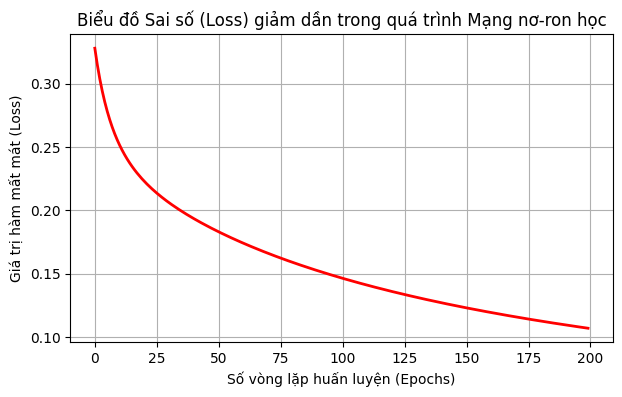

In [ ]:
import math
import matplotlib.pyplot as plt

# Khởi tạo trọng số lớp đầu ra ban đầu giống hệt trong báo cáo (Mục II.7)
v1 = 0.8
v2 = 0.7
v3 = 0.9
v4 = 0.6
b_o = -1.8

toc_do_hoc = 0.2 # Hệ số học (eta)
so_vong_lap = 200 # Số lần cho mạng học đi học lại (Epochs)
danh_sach_loss = []

for vong in range(1, so_vong_lap + 1):
    tong_loss = 0

    for dong in du_lieu_30_mau:
        # Bước 1: Chuẩn hóa dữ liệu
        X1 = (dong[2] - 1) / (10 - 1)
        X2 = (dong[3] - 0) / (5 - 0)
        X3 = (dong[4] - 0) / (2 - 0)
        X4 = (dong[6] - 3) / (5 - 3)
        X5 = 1 - (dong[7] - 1) / (45 - 1)
        y_thuc = dong[8]

        # Bước 2: Lan truyền xuôi (Forward Propagation)
        h1 = max(0, 0.5*X1 + 0.4*X2 + 0.3*X3 + 0.2*X4 + 0.1*X5 - 0.2)
        h2 = max(0, 0.2*X1 + 0.5*X2 + 0.6*X3 + 0.1*X4 + 0.2*X5 - 0.3)
        h3 = max(0, 0.3*X1 + 0.2*X2 + 0.5*X3 + 0.4*X4 + 0.1*X5 - 0.2)
        h4 = max(0, 0.1*X1 + 0.3*X2 + 0.4*X3 + 0.2*X4 + 0.3*X5 - 0.2)

        z_o = v1*h1 + v2*h2 + v3*h3 + v4*h4 + b_o
        y_mu = 1 / (1 + math.exp(-z_o))

        # Bước 3: Tính hàm mất mát Binary Cross-Entropy
        loss = - (y_thuc * math.log(y_mu) + (1 - y_thuc) * math.log(1 - y_mu))
        tong_loss = tong_loss + loss

        # Bước 4: Lan truyền ngược (Backpropagation) & Cập nhật trọng số
        # Công thức: w_moi = w_cu - toc_do_hoc * gradient
        sai_so = y_mu - y_thuc
        v1 = v1 - toc_do_hoc * (sai_so * h1) / 30
        v2 = v2 - toc_do_hoc * (sai_so * h2) / 30
        v3 = v3 - toc_do_hoc * (sai_so * h3) / 30
        v4 = v4 - toc_do_hoc * (sai_so * h4) / 30
        b_o = b_o - toc_do_hoc * sai_so / 30

    loss_trung_binh = tong_loss / 30
    danh_sach_loss.append(loss_trung_binh)

    # In kết quả sau mỗi 40 vòng lặp để theo dõi
    if vong == 1 or vong % 40 == 0:
        print(f"Vòng lặp {vong:<3}: Sai số (Loss) trung bình = {round(loss_trung_binh, 4)}")

print("\nTrọng số lớp đầu ra sau khi mạng đã học xong 200 vòng:")
print(f"v1 = {round(v1, 3)}, v2 = {round(v2, 3)}, v3 = {round(v3, 3)}, v4 = {round(v4, 3)}, b_o = {round(b_o, 3)}")

# Vẽ biểu đồ Loss giảm dần
plt.figure(figsize=(7, 4))
plt.plot(danh_sach_loss, color='red', linewidth=2)
plt.title("Biểu đồ Sai số (Loss) giảm dần trong quá trình Mạng nơ-ron học")
plt.xlabel("Số vòng lặp huấn luyện (Epochs)")
plt.ylabel("Giá trị hàm mất mát (Loss)")
plt.grid(True)
plt.show()

In [ ]:
import math

# Danh sách 5 sản phẩm cần tính xác suất gợi ý cho khách hàng (Mục II.12 - Trang 44)
# Cấu trúc mỗi dòng: [Tên sản phẩm, Lượt xem, Thêm giỏ, Đã mua, Đánh giá, Ngày từ lần mua]
danh_sach_san_pham = [
    ["Giày thể thao A", 10, 5, 2, 5, 1],
    ["Giày chạy bộ B",  9,  4, 2, 5, 2],
    ["Giày sneaker C",  8,  4, 1, 5, 2],
    ["Giày D",          7,  2, 1, 5, 5],
    ["Giày E",          4,  1, 0, 4, 14]
]

ket_qua_du_doan = []

# BƯỚC 1 -> 5: Chuẩn hóa và đưa từng sản phẩm vào mạng MLP để tính xác suất
for sp in danh_sach_san_pham:
    ten_sp   = sp[0]
    luot_xem = sp[1]
    them_gio = sp[2]
    luot_mua = sp[3]
    danh_gia = sp[4]
    ngay_mua = sp[5]

    # Chuẩn hóa Min-Max
    X1 = (luot_xem - 1) / (10 - 1)
    X2 = (them_gio - 0) / (5 - 0)
    X3 = (luot_mua - 0) / (2 - 0)
    X4 = (danh_gia - 3) / (5 - 3)
    X5 = 1 - (ngay_mua - 1) / (45 - 1)

    # Tính lớp ẩn (ReLU)
    h1 = max(0, 0.5*X1 + 0.4*X2 + 0.3*X3 + 0.2*X4 + 0.1*X5 - 0.2)
    h2 = max(0, 0.2*X1 + 0.5*X2 + 0.6*X3 + 0.1*X4 + 0.2*X5 - 0.3)
    h3 = max(0, 0.3*X1 + 0.2*X2 + 0.5*X3 + 0.4*X4 + 0.1*X5 - 0.2)
    h4 = max(0, 0.1*X1 + 0.3*X2 + 0.4*X3 + 0.2*X4 + 0.3*X5 - 0.2)

    # Tính xác suất quan tâm tại lớp Output (sử dụng trọng số đã học ở Ô 3)
    z_o = v1*h1 + v2*h2 + v3*h3 + v4*h4 + b_o
    xac_suat = (1 / (1 + math.exp(-z_o))) * 100

    ket_qua_du_doan.append([ten_sp, round(xac_suat, 1)])

# BƯỚC 6: Sắp xếp các sản phẩm theo xác suất giảm dần
ket_qua_du_doan.sort(key=lambda x: x[1], reverse=True)

# BƯỚC 7: Xếp hạng và đưa ra quyết định gợi ý Top-3 (Mục II.12 - Trang 44)
print("======================================================================")
print("BẢNG KẾT QUẢ XẾP HẠNG VÀ GỢI Ý SẢN PHẨM (Mục II.12 - Trang 44)")
print("======================================================================")
print(f"{'Sản phẩm':<18} | {'Xác suất quan tâm':<18} | {'Thứ hạng':<10} | {'Kết quả'}")
print("-" * 68)

thu_hang = 1
for item in ket_qua_du_doan:
    ten_sp = item[0]
    xac_suat = item[1]

    # Quy tắc gợi ý Top-3:
    if thu_hang <= 3 and xac_suat >= 50:
        ket_qua = "Gợi ý"
    elif xac_suat >= 50:
        ket_qua = "Có thể gợi ý"
    else:
        ket_qua = "Không ưu tiên"

    print(f"{ten_sp:<18} | {str(xac_suat) + '%':<18} | {thu_hang:<10} | {ket_qua}")
    thu_hang = thu_hang + 1

print("\n>>> HIỂN THỊ LÊN KHU VỰC 'SẢN PHẨM DÀNH CHO BẠN' (TOP-3):")
for i in range(3):
    print(f" {i+1}. {ket_qua_du_doan[i][0]} ({ket_qua_du_doan[i][1]}%)")

BẢNG KẾT QUẢ XẾP HẠNG VÀ GỢI Ý SẢN PHẨM (Mục II.12 - Trang 44)
Sản phẩm           | Xác suất quan tâm  | Thứ hạng   | Kết quả
--------------------------------------------------------------------
Giày thể thao A    | 99.9%              | 1          | Gợi ý
Giày chạy bộ B     | 99.7%              | 2          | Gợi ý
Giày sneaker C     | 98.1%              | 3          | Gợi ý
Giày D             | 92.9%              | 4          | Có thể gợi ý
Giày E             | 18.4%              | 5          | Không ưu tiên

>>> HIỂN THỊ LÊN KHU VỰC 'SẢN PHẨM DÀNH CHO BẠN' (TOP-3):
 1. Giày thể thao A (99.9%)
 2. Giày chạy bộ B (99.7%)
 3. Giày sneaker C (98.1%)
